In [1]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from matplotlib.lines import Line2D
from itertools import combinations
from umap import UMAP

In [2]:
y = pd.read_csv('Latent_svd_f50_k30_pc100.txt', index_col=0, header=None)
model = UMAP(n_components=2, n_neighbors=10, random_state=0)
y_2d = model.fit_transform(y)

label = pd.DataFrame(index=y.index)
label['type'] = [idx.split('/')[-1].split('_')[-1].replace('.txt','') for idx in label.index]
label['data'] = [idx.split('/')[-2] for idx in label.index]

/rhome/ma045/bigdata/.conda/envs/virenv3/lib/python3.6/site-packages/numba/np/ufunc/parallel.py:365: NumbaWarning: The TBB threading layer requires TBB version 2019.5 or later i.e., TBB_INTERFACE_VERSION >= 11005. Found TBB_INTERFACE_VERSION = 10002. The TBB threading layer is disabled.
  warnings.warn(problem)


In [3]:
cell_type = sorted(label['type'].value_counts().index)
cell_batch = sorted(label['data'].value_counts().index)

color = ['#d8211c', '#f6c14d', '#3cb44b', '#add8e6', '#c79fef',]
plot_color = pd.DataFrame({'color': color}, index = cell_type + sorted(cell_batch))

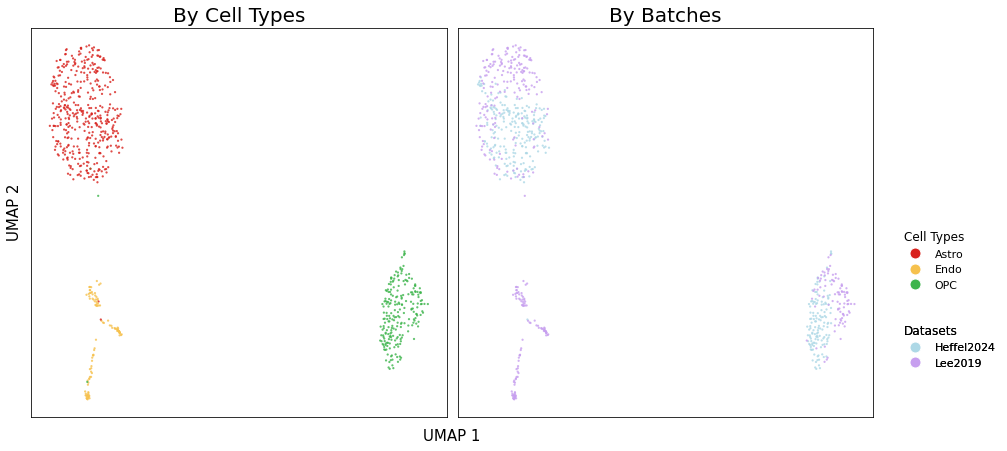

In [4]:
ds = 5
num = 3

fig, axes = plt.subplots(1,2,figsize=(12,6))
for i,ax in enumerate(axes.flatten()):
    ax.tick_params(axis='both', which='both', length=0)
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    
label_color = np.empty(len(y))
label_color = label_color.astype('str')

for i,x in enumerate(label['type'].value_counts().index):
    cell = (label['type'].astype('str')==x)
    label_color[cell] = plot_color.loc[x]['color']
axes[0].scatter(y_2d[:,0], y_2d[:,1], c=label_color, s=ds, edgecolors='none', alpha=0.8, label=x, rasterized=True)
axes[0].set_title('By Cell Types', fontsize=20)

for i,x in enumerate(cell_batch):
    cell = (label['data'].astype('str')==x)
    axes[1].scatter(y_2d[cell,0], y_2d[cell,1], c=plot_color.loc[x]['color'], s=ds, edgecolors='none', alpha=0.8, label=x, rasterized=True)
axes[1].set_title('By Batches', fontsize=20)

legend_elements1 = []
for t in plot_color.index[:num]:
    legend_elements1.append(Line2D([0], [0], marker='o', color='w', label=t, markerfacecolor=plot_color.loc[t]['color'], markersize=11))               
legend1 = plt.legend(handles=legend_elements1, prop={'size': 11}, loc='lower left', bbox_to_anchor=(1.05,0.3), title="Cell Types",frameon=False)
legend1._legend_box.align = "left"
plt.gca().add_artist(legend1)
plt.setp(legend1.get_title(), fontsize='12')  

legend_elements2 = []
for t in plot_color.index[num:]:
    legend_elements2.append(Line2D([0], [0], marker='o', color='w', label=t, markerfacecolor=plot_color.loc[t]['color'], markersize=11))
legend2 = plt.legend(handles=legend_elements2, prop={'size': 11}, loc='lower left', bbox_to_anchor=(1.05,0.1), title="Datasets",frameon=False)
legend2._legend_box.align = "left"
plt.gca().add_artist(legend2)
plt.setp(legend2.get_title(), fontsize='12')  


fig.text(0.5, -0.03, 'UMAP 1', ha='center', fontsize=15)
fig.text(-0.015, 0.5, 'UMAP 2', va='center', fontsize=15, rotation='vertical')
plt.tight_layout()
plt.show() 